<a href="https://colab.research.google.com/github/judithwang021/judith-6070/blob/main/WeeklyModules/Week07/Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from pathlib import Path
!pip -q install dataframe_image
import dataframe_image as dfi

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('github_token')
owner = 'judithwang021' # Replace with the GitHub repository owner
repository = 'judith-6070' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/judith-6070/judith-6070


In [29]:
file_path = Path("/content/judith-6070/data/InternetSales.csv")
df = pd.read_csv(file_path, encoding='latin1')
df.head()

/tmp/ipykernel_1969/4294420684.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding='latin1')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [30]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

In [31]:
df['year'] = df['OrderDate'].dt.year

In [32]:
ysales = df.groupby('year')['SalesAmount'].sum()

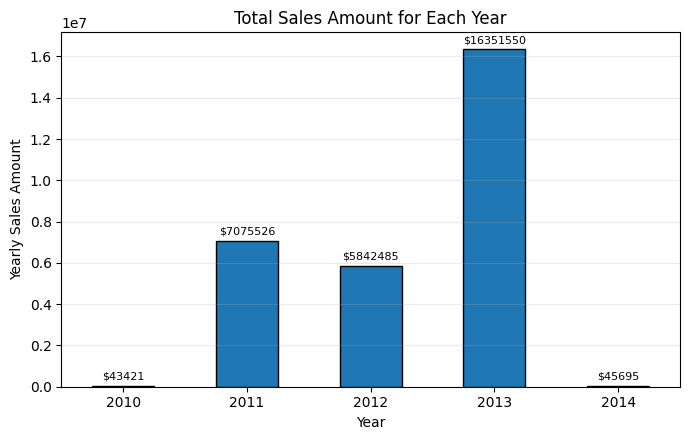

In [33]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ysales.plot(kind="bar", figsize=(7, 4.5), edgecolor="black")
plt.xlabel("Year")
plt.ylabel("Yearly Sales Amount")
plt.title("Total Sales Amount for Each Year")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.0f', padding=3, fontsize=8)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

fig.savefig('Yearly Sales Amount.pdf')
plt.show()